In [33]:
import matplotlib.pyplot as plt
import numpy as np

# Model parameters
n = 101  # Number of positions
D = 1.0  # Total demand
c0 = 0.2  # Cost per pizza
k = 1.0  # Travel cost
p_max = 1.0  # Max price
dp = 0.05  # Price step

demand_per_customer = D / n
road = np.linspace(-1, 1, n)
dx = road[1] - road[0]  # Spatial grid step

# Random initial states
x1, x2 = np.random.choice(road), np.random.choice(road)
p1, p2 = 0.5, 0.5


def calculate_profit(x1, x2, p1, p2):
    total_cost_1 = p1 + k * np.abs(road - x1)
    total_cost_2 = p2 + k * np.abs(road - x2)

    customers_1 = np.sum(total_cost_1 < total_cost_2)
    customers_2 = np.sum(total_cost_2 < total_cost_1)

    ties = np.sum(np.isclose(total_cost_1, total_cost_2))

    customers_1 += 0.5 * ties
    customers_2 += 0.5 * ties

    Q1 = customers_1 * demand_per_customer
    Q2 = customers_2 * demand_per_customer

    profit_1 = (p1 - c0) * Q1
    profit_2 = (p2 - c0) * Q2

    return profit_1, profit_2


def best_simultaneous_move(x1, x2, p1, p2, firm):
    """Evaluates the 9 local combinations (x +- dx, p +- dp) for a given firm."""
    curr_x = x1 if firm == 1 else x2
    curr_p = p1 if firm == 1 else p2
    curr_idx = np.where(road == curr_x)[0][0]

    best_x, best_p = curr_x, curr_p
    best_profit = (
        calculate_profit(x1, x2, p1, p2)[0]
        if firm == 1
        else calculate_profit(x1, x2, p1, p2)[1]
    )

    # 3 location choices: left, stay, right
    for dx_idx in [-1, 0, 1]:
        new_idx = curr_idx + dx_idx
        if 0 <= new_idx < len(road):
            cand_x = road[new_idx]

            # 3 price choices: down, stay, up
            for dp_val in [-dp, 0, dp]:
                cand_p = curr_p + dp_val

                if 0 <= cand_p <= p_max:
                    if firm == 1:
                        prof = calculate_profit(cand_x, x2, cand_p, p2)[0]
                    else:
                        prof = calculate_profit(x1, cand_x, p1, cand_p)[1]

                    if prof > best_profit:
                        best_profit = prof
                        best_x, best_p = cand_x, cand_p

    return best_x, best_p


# Tracking history
history_x1, history_x2 = [x1], [x2]
history_p1, history_p2 = [p1], [p2]

# Main Loop: Simultaneous adjustment
max_iterations = 1000
for iteration in range(max_iterations):
    old_x1, old_p1 = x1, p1
    old_x2, old_p2 = x2, p2

    # Best responses given current state of opponent
    x1, p1 = best_simultaneous_move(old_x1, old_x2, old_p1, old_p2, 1)
    x2, p2 = best_simultaneous_move(old_x1, old_x2, old_p1, old_p2, 2)

    history_x1.append(x1)
    history_x2.append(x2)
    history_p1.append(p1)
    history_p2.append(p2)

    # Stop if equilibrium is reached
    if x1 == old_x1 and x2 == old_x2 and p1 == old_p1 and p2 == old_p2:
        break

profit_1, profit_2 = calculate_profit(x1, x2, p1, p2)

print(f"Converged in {iteration + 1} iterations.")
print(f"Firm 1 -> Position: {x1:.2f}, Price: {p1:.2f}, Profit: {profit_1:.3f}")
print(f"Firm 2 -> Position: {x2:.2f}, Price: {p2:.2f}, Profit: {profit_2:.3f}")

Converged in 52 iterations.
Firm 1 -> Position: 0.00, Price: 0.25, Profit: 0.025
Firm 2 -> Position: 0.00, Price: 0.25, Profit: 0.025


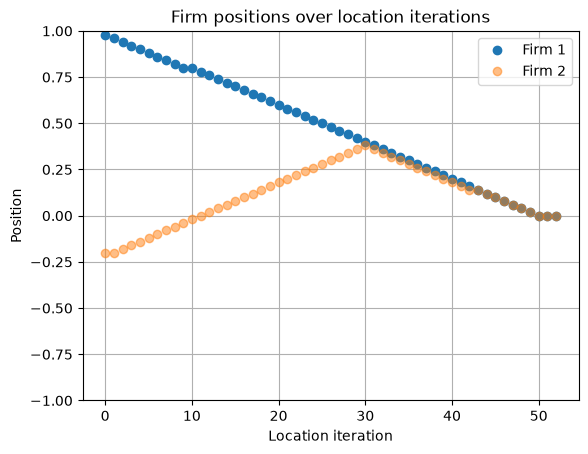

In [34]:
import matplotlib.pyplot as plt

plt.plot(history_x1, marker="o", linestyle="None", label="Firm 1")
plt.plot(history_x2, marker="o", linestyle="None", label="Firm 2", alpha=0.5)

plt.xlabel("Location iteration")
plt.ylabel("Position")
plt.title("Firm positions over location iterations")

plt.ylim(-1, 1)
plt.legend()
plt.grid()

plt.show()